# Pianificazione patrimoniale Monte Carlo: esempio guidato

La **famiglia Rossi** (45 anni) ha 180.000 € investiti e ne risparmia 14.000 l'anno. Vorrebbe andare in pensione a 67 anni con un capitale di almeno **550.000 €** e mantenere un tenore di vita di **40.000 € l'anno**, di cui 21.000 coperti dalla pensione pubblica. Nel frattempo dovrà pagare l'università a due figli.

Rispondiamo a quattro domande:
1. Con quale probabilità raggiunge il capitale obiettivo?
2. Il patrimonio basta fino a 95 anni, tenendo conto di inflazione, costi e imposte?
3. Quanto può spendere in pensione con 9 probabilità su 10?
4. Quali leve migliorano di più il piano?

Tutti gli importi sono in **euro di oggi**.

In [1]:
import pandas as pd
import plotly.io as pio

from wealth_planner import esempio_rossi, genera, simula
from wealth_planner import analisi as an
from wealth_planner.report import analizza, grafico_griglia, grafico_probabilita, grafico_sequenza, grafico_ventaglio

pio.renderers.default = "png"  # immagini statiche, visibili anche su GitHub
pd.options.display.float_format = "{:,.0f}".format

## 1. Ipotesi e scenari di mercato

Le ipotesi sono raccolte in un oggetto `Piano`; si possono leggere anche da un file TOML (vedi `examples/famiglia_rossi.toml`). I mercati sono simulati con rendimenti lognormali correlati e un 10% di anni turbolenti a volatilità doppia; l'inflazione segue un processo autoregressivo.

In [2]:
piano = esempio_rossi()
piano.flussi

Flussi(patrimonio_iniziale=180000, versamento_annuo=14000, crescita_versamenti=0.01, spesa_annua=40000, pensione_pubblica=21000, eta_pensione_pubblica=None, costo_fiscale_iniziale=None, strategia='fisso', tasso_prelievo=0.04, soglia_guardrail=0.2, correzione_guardrail=0.1, taglio_massimo=0.3)

In [3]:
scenari = genera(piano.mercato, piano.anni, n=5_000, seed=42)
r = simula(piano, scenari)
pd.DataFrame(scenari.rendimenti.reshape(-1, 3), columns=[a.nome for a in piano.mercato.asset.values()]).describe(
    percentiles=[0.01, 0.5, 0.99]).T[["mean", "std", "1%", "50%", "99%"]].style.format("{:.1%}")

,mean,std,1%,50%,99%
Azioni globali,7.0%,16.0%,-27.8%,5.9%,51.2%
Obbligazioni area euro,3.0%,5.5%,-10.0%,2.9%,17.2%
Liquidità e monetario,2.2%,1.0%,-0.3%,2.2%,4.7%


## 2. L'obiettivo alla pensione

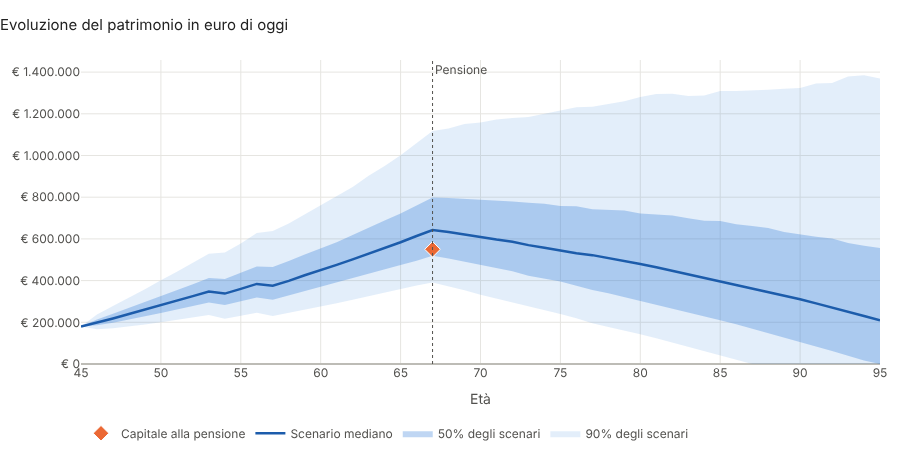

In [4]:
a = analizza(piano, n_simulazioni=5_000)
grafico_ventaglio(a).show(width=900)

In [5]:
print(f"Probabilità di avere almeno 550.000 € a 67 anni: {an.probabilita_obiettivo(r):.0%}")
print(f"Versamento annuo necessario per 8 casi su 10:   € {a.versamento_necessario:,.0f}")

Probabilità di avere almeno 550.000 € a 67 anni: 69%
Versamento annuo necessario per 8 casi su 10:   € 16,086


Lo scenario mediano supera l'obiettivo, ma in circa 3 casi su 10 il capitale resta sotto: per arrivarci con buona sicurezza servirebbero circa **2.000 € in più all'anno** di risparmio.

## 3. Sostenibilità in pensione

In [6]:
ind = an.sintesi(r)
pd.Series(ind).to_frame("Valore").style.format("{:,.3f}")

,Valore
Probabilità di successo,0.741
Probabilità obiettivo,0.688
Rischio di longevità,0.100
Patrimonio alla pensione (mediana),"642,472.890"
Patrimonio alla pensione (P10),"434,033.054"
Patrimonio finale (mediana),"210,109.112"
Patrimonio finale (P10),0.000
Patrimonio finale (P90),"1,004,622.659"
Età di esaurimento (mediana se esaurito),90.000
Prelievo annuo medio in pensione,"19,000.000"


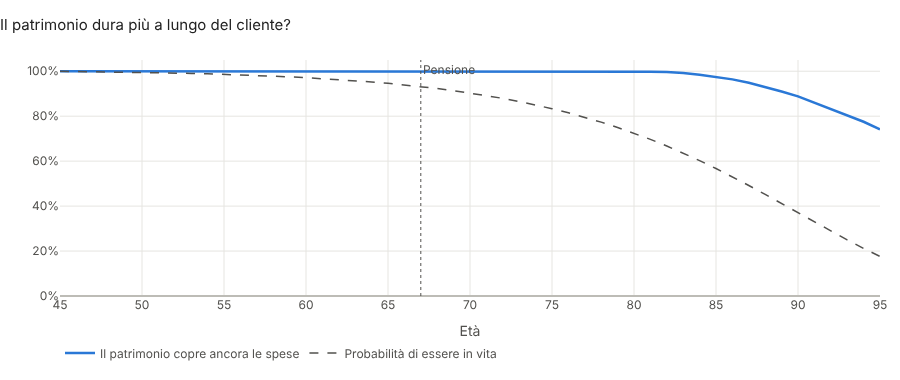

In [7]:
grafico_probabilita(a).show(width=900)

Il patrimonio basta fino a 95 anni nel **74%** degli scenari. Ma il rischio che conta davvero per il cliente, **restare senza risorse mentre è ancora in vita**, è del **10%**: in molti scenari sfavorevoli il patrimonio si esaurisce a un'età che il cliente ha poche probabilità di raggiungere.

L'inflazione pesa: alla pensione 1.000 € di oggi varranno circa 650 €. Il rendimento reale mediano del portafoglio, al netto di costi e bollo, è intorno al 2% annuo.

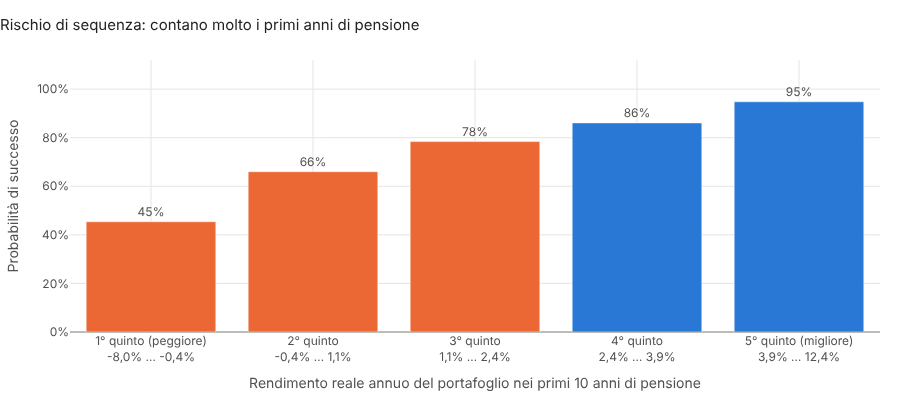

In [8]:
grafico_sequenza(a).show(width=900)

**Rischio di sequenza**: se i primi dieci anni di pensione sono i peggiori, il piano riesce in meno della metà dei casi; se sono i migliori, in 19 casi su 20.

## 4. Leve a disposizione

Spesa sostenibile con 9 probabilità su 10: € 36,455 l'anno (prevista € 40.000)


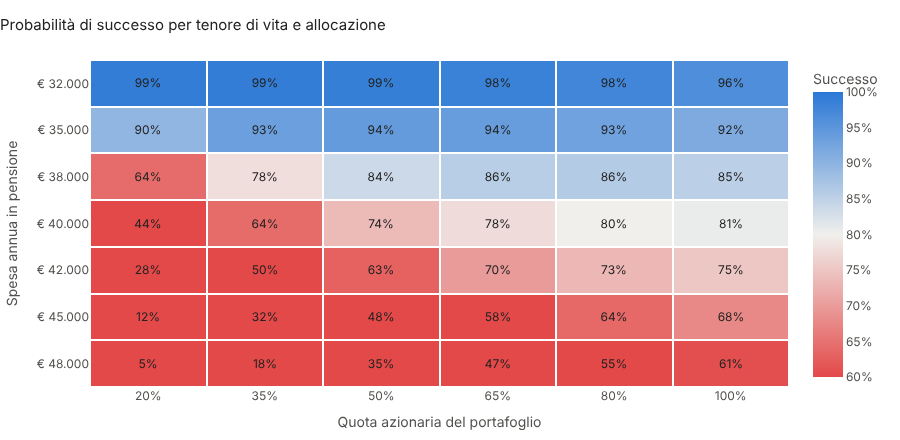

In [9]:
print(f"Spesa sostenibile con 9 probabilità su 10: € {a.prelievo_sostenibile:,.0f} l'anno (prevista € 40.000)")
grafico_griglia(a).show(width=900)

In [10]:
a.strategie.style.format({"Probabilità di successo": "{:.0%}", "Spesa annua media": "€ {:,.0f}",
                          "Spesa nell'anno peggiore (P10)": "€ {:,.0f}", "Patrimonio finale (mediana)": "€ {:,.0f}"})

,Probabilità di successo,Spesa annua media,Spesa nell'anno peggiore (P10),Patrimonio finale (mediana)
Importo fisso indicizzato,74%,"€ 40,000","€ 21,000","€ 210,109"
"4,0% del patrimonio",100%,"€ 38,712","€ 26,869","€ 264,596"
Fisso con guardrail,93%,"€ 36,957","€ 34,300","€ 332,769"


In [11]:
a.leve.style.format({"Probabilità di successo": "{:.0%}", "Probabilità obiettivo": "{:.0%}",
                     "Patrimonio finale (mediana)": "€ {:,.0f}"})

,Probabilità di successo,Probabilità obiettivo,Patrimonio finale (mediana)
Piano attuale,74%,69%,"€ 210,109"
Spesa in pensione −10%,91%,69%,"€ 387,835"
Versamenti +25%,88%,86%,"€ 391,068"
Pensione 2 anni più tardi,87%,69%,"€ 347,892"
"Azioni −20 punti, senza life-cycle",74%,67%,"€ 201,437"
"Azioni +20 punti, senza life-cycle",80%,73%,"€ 615,604"
Prelievi con guardrail,93%,69%,"€ 332,769"


**Conclusione per il cliente:** il piano è fattibile ma non ancora solido. Le leve più efficaci sono una **spesa in pensione più flessibile** (guardrail: tagli del 10% solo negli anni difficili, che portano il successo oltre il 90% con una spesa media di circa 37.000 €), una spesa di partenza intorno a 36.000 € oppure **qualche migliaio di euro di risparmio in più** all'anno. Ridurre le azioni senza cambiare altro non aiuta: con un orizzonte di 50 anni, la componente azionaria serve a battere l'inflazione.

Il report completo per il cliente si genera con:

```bash
wealth-planner --demo --cliente "Mario Rossi"
```